In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv("iris.csv")
print("first 5 rows : ")
print(df.head())

print("shape : ")
print(df.shape)

print("dataset information : ")
print(df.info())

print("statistical analysis : ")
print(df.describe())

first 5 rows : 
   sepal.length  sepal.width  petal.length  petal.width species
0           5.1          3.5           1.4          0.2  Setosa
1           4.9          3.0           1.4          0.2  Setosa
2           4.7          3.2           1.3          0.2  Setosa
3           4.6          3.1           1.5          0.2  Setosa
4           5.0          3.6           1.4          0.2  Setosa
shape : 
(150, 5)
dataset information : 
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal.length  150 non-null    float64
 1   sepal.width   150 non-null    float64
 2   petal.length  150 non-null    float64
 3   petal.width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.2 KB
None
statistical analysis : 
       sepal.length  sepal.width  petal.length  petal.width
count    150.000000   150.00

In [7]:
# data cleaning

df.columns = df.columns.str.strip() #remove extra spaces from column names

cols = [c for c in df.columns if "sepel" in c.lower() or "petal" in c.lower()] #select sepal and petal columns
df[cols] = df[cols].apply(pd.to_numeric, errors = "coerce") #convert values into numbers

df[cols] = df[cols].fillna(df[cols].mean())

print("missing values after cleaning : ")
print(df.isnull().sum())

df = df.drop_duplicates()

print("cleaned data : ")
print(df.head())

missing values after cleaning : 
sepal.length    0
sepal.width     0
petal.length    0
petal.width     0
species         0
dtype: int64
cleaned data : 
   sepal.length  sepal.width  petal.length  petal.width species
0           5.1          3.5           1.4          0.2  Setosa
1           4.9          3.0           1.4          0.2  Setosa
2           4.7          3.2           1.3          0.2  Setosa
3           4.6          3.1           1.5          0.2  Setosa
4           5.0          3.6           1.4          0.2  Setosa


In [9]:
# Correlation Matrix
corr = df[cols].corr()

print("Correlation Matrix:")
print(corr)

Correlation Matrix:
              petal.length  petal.width
petal.length      1.000000     0.962772
petal.width       0.962772     1.000000


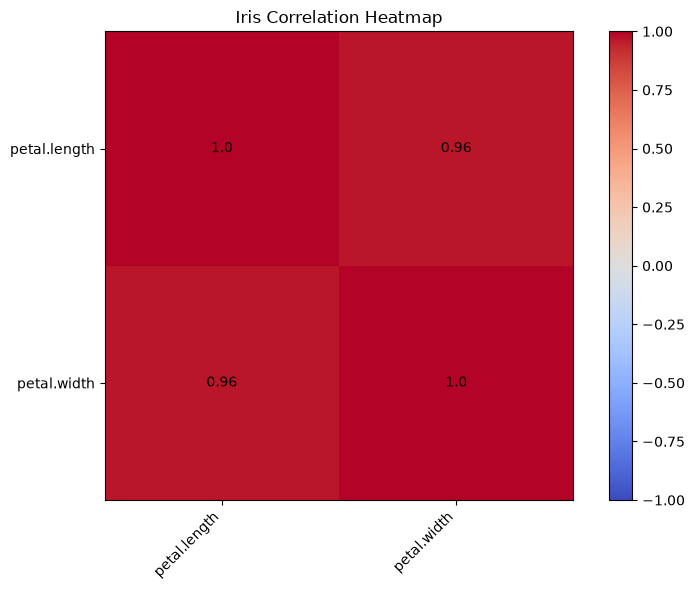

In [11]:
# Heatmap
plt.figure(figsize=(8, 6))

plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()

plt.xticks(range(len(cols)), cols, rotation=45, ha="right")
plt.yticks(range(len(cols)), cols)

for i in range(len(cols)):
    for j in range(len(cols)):
        plt.text(j, i, round(corr.iloc[i, j], 2),
                 ha="center", va="center")

plt.title("Iris Correlation Heatmap")
plt.tight_layout()
plt.show()

# Save Cleaned Dataset
df.to_csv("iris_cleaned.csv", index=False)